In [1]:
import cv2
import numpy as np
import pandas as pd
import scipy as sc
import matplotlib.pyplot as plt
from tqdm import tqdm
#%matplotlib tk

vid_filename = 'D:\\Study\\TAU\\Year 3\\Winter Semester\\Lab C1\\Active Matter\\active-matter-lab-main\\active-matter-lab-main\\hexbug_1.mp4'
cap = cv2.VideoCapture(vid_filename)

NF = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
print(NF)
t_start = cap.get(cv2.CAP_PROP_POS_MSEC) / 1000  # Convert ms to seconds

x_t = np.zeros(NF)
y_t = np.zeros(NF)
t = np.zeros(NF)


# Read and display the first frame with interactive click
ret, frame = cap.read()
if ret:
    fig, ax = plt.subplots()
    ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    plt.show()


def frame_isolate_green(image, dark_green=True):
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

    if dark_green:
        # Define thresholds for dark green
        lower_bound = np.array([35, 100, 100])
        upper_bound = np.array([85, 255, 255])
    else:
        # Define thresholds (converted from MATLAB values)
        lower_bound = np.array([37, 190, 127])  # Approximate conversion
        upper_bound = np.array([76, 255, 255])

    mask = cv2.inRange(hsv, lower_bound, upper_bound)
    masked_image = cv2.bitwise_and(image, image, mask=mask)
    return mask, masked_image

def frame_isolate_orange(image, dark_orange=False):
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

    if dark_orange:
        # Define thresholds for dark orange
        lower_bound = np.array([0, 150, 150])
        upper_bound = np.array([10, 255, 255])
    else:
        # Define thresholds (converted from MATLAB values)
        lower_bound = np.array([1, 175, 175])
        upper_bound = np.array([20, 255, 255])

    mask = cv2.inRange(hsv, lower_bound, upper_bound)
    masked_image = cv2.bitwise_and(image, image, mask=mask)
    return mask, masked_image

def find_circles(frame, isolate_green=False, isolate_orange=False, min_r=10, max_r=20):

    if isolate_green:
        mask, _ = frame_isolate_green(frame)

        blurred = cv2.GaussianBlur(mask, (9, 9), 2)
        edges = cv2.Canny(blurred, 50, 150)

        circles = cv2.HoughCircles(edges, cv2.HOUGH_GRADIENT, dp=1.2, minDist=15,
                            param1=50, param2=20, minRadius=min_r, maxRadius=max_r)
    elif isolate_orange:
        mask, _ = frame_isolate_orange(frame)

        blurred = cv2.GaussianBlur(mask, (9, 9), 2)
        edges = cv2.Canny(blurred, 50, 150)

        circles = cv2.HoughCircles(edges, cv2.HOUGH_GRADIENT, dp=1.2, minDist=15,
                            param1=50, param2=20, minRadius=min_r, maxRadius=max_r)
    else:
        frame_gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        frame_gray_norm = cv2.normalize(frame_gray, None, 0, 255, cv2.NORM_MINMAX)

        circles = cv2.HoughCircles(frame_gray_norm, cv2.HOUGH_GRADIENT, 1, minDist=20,
                                param1=50, param2=30, minRadius=min_r, maxRadius=max_r)

    return circles

-1


ValueError: negative dimensions are not allowed

In [ ]:
%matplotlib inline

min_r, max_r = 35, 45
isolate_green = False
isolate_orange = False

# Process the first 5 frames
cap.set(cv2.CAP_PROP_POS_FRAMES, 0)
for time_idx in range(3):
    t[time_idx] = cap.get(cv2.CAP_PROP_POS_MSEC) / 1000
    ret, frame = cap.read()
    if not ret:
        break

    circles = find_circles(frame, isolate_green=isolate_green, isolate_orange=isolate_orange, min_r=min_r, max_r=max_r)

    if circles is not None:
        circles = np.uint16(np.around(circles))
        for circ_stats in circles[0, :]:
            center = (circ_stats[0], circ_stats[1]) 
            radius = circ_stats[2]
            cv2.circle(frame, center, radius, (255, 0, 0), 20)
            x_t[time_idx], y_t[time_idx] = center
            print(time_idx, circ_stats)

    plt.figure()
    plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    plt.show()

[1.         0.99497475 0.99127313 ... 0.00733636 0.00708511 0.00732474]


C:\Users\user\AppData\Local\Temp\ipykernel_5288\3615643772.py:6: RuntimeWarning: invalid value encountered in divide
  n_vec = v / np.array((v_mag , v_mag)).T


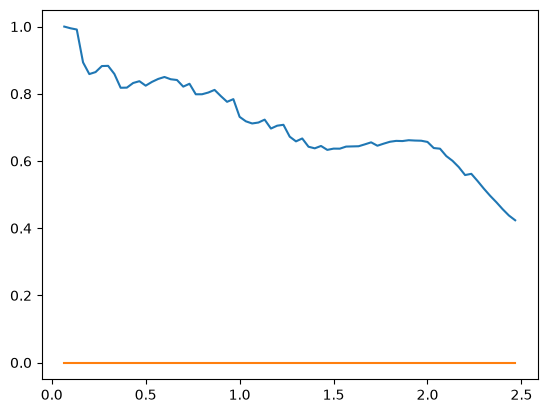

In [ ]:
df = pd.read_csv("hexbug_1_circles.csv")
v_x = (pd.array(df["x"][1:]) - pd.array(df["x"][:-1])) * 30 #px/s
v_y = (pd.array(df["y"][1:]) - pd.array(df["y"][:-1])) * 30 #px/s
v = np.array((v_x, v_y)).T
v_mag = np.sqrt(v_x**2 + v_y**2)
n_vec = v / np.array((v_mag , v_mag)).T
last = n_vec[0]
for i in range(len(n_vec)): #this is assuming a particle doesn't change it's orientation when it's at rest
    if v_mag[i] == 0:
        n_vec[i] = last
    else:
        last = n_vec[i]

auto_corr = []
for i in range(len(n_vec[1:])):
    auto_corr.append(n_vec[i] @ n_vec[0].T)

auto_corr = np.array(auto_corr)
auto_corr_avg = np.array([np.mean(auto_corr[:i + 1]) for i in range(len(auto_corr))])